# **Sumi's Music Universe:** An Exploratory Data Analysis of My Music Streaming Behavior

## Purpose
In this notebook, approximately 6-months of my personal music streaming data is used to understand and explore my listening behavior, discovery habits, repetition patterns, time-based trends, source routes, session dynamics, track lifecycles, and recommendation opportunities. The analysis is built from processed Parquet tables generated by the project pipeline. The goal is to understand my behavior as a listener, assess the quality of the data present, and use the insights found here to develop an interactive dashboard with a built in recommendation system.

## Imports and Configuration

In [107]:
import warnings
from pathlib import Path

import numpy
import pandas
import plotly.express as plot
import plotly.graph_objects as graph
import plotly.io as plot_io
from IPython.display import HTML, Markdown, display

warnings.filterwarnings("ignore")

In [108]:
pandas.set_option("display.max_columns", 160)
pandas.set_option("display.max_rows", 120)
pandas.set_option("display.width", 220)
pandas.set_option("display.float_format", lambda value: f"{value:,.3f}")

In [160]:
blue_set = ["#dff4ff", "#bde8ff", "#8fd3ff", "#5ab8ff", "#2f93e6", "#1769aa", "#0d3f66"]

blue_theme = graph.layout.Template(
    layout=graph.Layout(
        colorway=blue_set,
        font=dict(family="Inter, Segoe UI, Arial", color="#18324a"),
        paper_bgcolor="rgba(238, 248, 255, 0.70)",
        plot_bgcolor="rgba(248, 252, 255, 0.72)",
    )
)

plot_io.templates["blue_glass"] = blue_theme
plot_io.templates.default = "blue_glass"

page_style = """
<style>
body, .jp-Notebook, .notebook_app {
    background: linear-gradient(135deg, #eaf7ff 0%, #f7fbff 45%, #dcefff 100%) !important;
}
.glass-title {
    padding: 28px 30px;
    margin: 10px 0 22px 0;
    border: 1px solid rgba(86, 158, 215, 0.28);
    border-radius: 22px;
    background: linear-gradient(135deg, rgba(255, 255, 255, 0.72), rgba(209, 235, 255, 0.46));
    box-shadow: 0 18px 45px rgba(43, 116, 171, 0.16);
    backdrop-filter: blur(14px);
}
.glass-title h1 {
    margin: 0;
    color: #0e426d;
    font-size: 34px;
    letter-spacing: -0.04em;
}
.glass-title p {
    margin: 8px 0 0 0;
    color: #38627f;
    font-size: 16px;
}
</style>
"""

display(HTML(page_style))
display(
    HTML(
        "<div class='glass-title'>"
        "<h1>Sumi’s Music Universe</h1>"
        "<h4>An Exploratory Data Analysis of My Music Streaming Behavior</h4>"
        "</div>"
    )
)

In [110]:
# depends on device for now, might remove later
def find_root():
    here = Path.cwd()

    for path in [here, *here.parents]:
        if (path / "data").exists():
            return path

    mac = Path.home() / "Documents" / "Coding" / "music-analytics"

    if mac.exists():
        return mac

    if Path("/mnt/data").exists():
        return Path("/mnt/data")

    return here

In [111]:
def read_table(name):
    paths = [
        proc_root / name,
        proc_root / "analytics" / name,
        data_root / "processed" / name,
        chat_root / name,
        root / name,
    ]

    for path in paths:
        if path.exists():
            data = pandas.read_parquet(path)
            print(f"Loaded {name} with {len(data):,} rows and {data.shape[1]:,} columns.")
            return data

    print(f"Missing {name}.")
    return pandas.DataFrame()

In [112]:
root = find_root()
data_root = root / "data"
proc_root = data_root / "processed"
chat_root = Path("/mnt/data")
report_root = root / "reports"
eda_root = report_root / "exploratory_data_analysis"
fig_root = report_root / "figures" / "exploratory_data_analysis"
tab_root = report_root / "tables" / "exploratory_data_analysis"

for folder in [eda_root, fig_root, tab_root]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {root}.")
print(f"EDA Figure Directory: {fig_root}.")
print(f"EDA Table Directory: {tab_root}.")

Project Root: /Users/Sumaitat/Documents/Coding/music-analytics.
EDA Figure Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis.
EDA Table Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/exploratory_data_analysis.


In [113]:
albums = read_table("albums.parquet")
artists = read_table("artists.parquet")
daily_tracks = read_table("daily_tracks.parquet")
days = read_table("days.parquet")
features = read_table("features.parquet")
genres = read_table("genres.parquet")
hours = read_table("hours.parquet")
library = read_table("library.parquet")
life = read_table("life.parquet")
playlists = read_table("playlists.parquet")
playlist_tracks = read_table("playlist_tracks.parquet")
plays = read_table("plays.parquet")
profile = read_table("profile.parquet")
candidates = read_table("recommend_candidates.parquet")
recommend_profile = read_table("recommend_profile.parquet")
recommend_sample = read_table("recommend_sample.parquet")
recommendations = read_table("recommendations.parquet")
sessions = read_table("sessions.parquet")
sources = read_table("sources.parquet")

Loaded albums.parquet with 1,853 rows and 11 columns.
Loaded artists.parquet with 996 rows and 16 columns.
Loaded daily_tracks.parquet with 5,042 rows and 22 columns.
Loaded days.parquet with 143 rows and 12 columns.
Loaded features.parquet with 2,962 rows and 44 columns.
Loaded genres.parquet with 71 rows and 12 columns.
Loaded hours.parquet with 155 rows and 9 columns.
Loaded library.parquet with 10,633 rows and 15 columns.
Loaded life.parquet with 2,962 rows and 18 columns.
Loaded playlists.parquet with 144 rows and 5 columns.
Loaded playlist_tracks.parquet with 16,687 rows and 4 columns.
Loaded plays.parquet with 10,454 rows and 42 columns.
Loaded profile.parquet with 12 rows and 3 columns.
Loaded recommend_candidates.parquet with 2,962 rows and 22 columns.
Loaded recommend_profile.parquet with 8 rows and 3 columns.
Loaded recommend_sample.parquet with 132 rows and 3 columns.
Loaded recommendations.parquet with 17,980 rows and 23 columns.
Loaded sessions.parquet with 448 rows and 1

## Helper Functions

In [114]:
def plain_time(series):
    time = pandas.to_datetime(series, errors="coerce")

    if getattr(time.dt, "tz", None) is not None:
        time = time.dt.tz_convert(None)

    return time

In [115]:
def set_time(data, cols):
    data = data.copy()

    for col in cols:
        if col in data.columns:
            data[col] = plain_time(data[col])

    return data

In [116]:
def has_cols(data, cols):
    return all(col in data.columns for col in cols)

In [117]:
def rate_text(value):
    if pandas.isna(value):
        return "0.0%"

    return f"{value:.1%}"

In [118]:
def number_text(value):
    if pandas.isna(value):
        return "0"

    if abs(float(value)) >= 1000:
        return f"{value:,.0f}"

    return f"{value:,.2f}"

In [119]:
def safe_mean(data, col):
    if data.empty or col not in data.columns:
        return numpy.nan

    return data[col].mean()

In [120]:
def top_name(data, name, by):
    if data.empty or name not in data.columns or by not in data.columns:
        return "Unknown"

    row = data.sort_values(by, ascending=False).head(1)

    if row.empty:
        return "Unknown"

    return str(row[name].iloc[0])

In [121]:
def show_table(data, title, rows=12):
    display(Markdown(f"### {title}"))

    if data.empty:
        print(f"{title} is empty.")
        return

    view = data.head(rows)

    view = view.style.set_table_styles(
        [
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "separate"),
                    ("border-spacing", "0"),
                    ("border", "1px solid rgba(86, 158, 215, 0.28)"),
                    ("border-radius", "14px"),
                    ("overflow", "hidden"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("background", "rgba(206, 234, 255, 0.72)"),
                    ("color", "#0e426d"),
                    ("font-weight", "700"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("background", "rgba(255, 255, 255, 0.58)"),
                    ("color", "#18324a"),
                ],
            },
        ]
    )

    display(view)

In [122]:
def style_chart(chart, title, subtitle="", height=520):
    full_title = f"<b>{title}</b>"

    if subtitle:
        full_title = f"<b>{title}</b><br><sup>{subtitle}</sup>"

    chart.update_layout(
        title=dict(text=full_title, x=0.02, xanchor="left"),
        height=height,
        margin=dict(l=55, r=35, t=88, b=55),
        hoverlabel=dict(
            bgcolor="rgba(241, 249, 255, 0.96)",
            bordercolor="#7dbde8",
            font_size=12,
            font_family="Inter, Segoe UI, Arial",
        ),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1,
        ),
    )

    chart.update_xaxes(
        showgrid=True,
        gridcolor="rgba(52, 119, 172, 0.16)",
        zeroline=False,
        title_font=dict(color="#244f73"),
    )

    chart.update_yaxes(
        showgrid=True,
        gridcolor="rgba(52, 119, 172, 0.16)",
        zeroline=False,
        title_font=dict(color="#244f73"),
    )

    return chart

In [123]:
def save_chart(chart, name):
    path = fig_root / f"{name}.html"
    chart.write_html(path)
    print(f"Saved chart to {path}.")

    return path

In [124]:
def show_chart(chart, name, title, subtitle="", height=520):
    chart = style_chart(chart, title, subtitle, height)
    chart.show()
    save_chart(chart, name)

    return chart

## Load Datasets

In [125]:
plays = set_time(plays, ["played_at", "start_at", "received_at", "date"])
days = set_time(days, ["date"])
daily_tracks = set_time(daily_tracks, ["date", "played_at"])
features = set_time(features, ["first_play", "last_play", "added_at", "release_at"])
life = set_time(life, ["first_play", "last_play"])
library = set_time(library, ["added_at", "release_at"])
sessions = set_time(sessions, ["start", "end"])
artists = set_time(artists, ["first_play", "last_play"])
albums = set_time(albums, ["first_play", "last_play"])

In [126]:
tables = {
    "albums": albums,
    "artists": artists,
    "daily_tracks": daily_tracks,
    "days": days,
    "features": features,
    "genres": genres,
    "hours": hours,
    "library": library,
    "life": life,
    "playlists": playlists,
    "playlist_tracks": playlist_tracks,
    "plays": plays,
    "profile": profile,
    "recommend_candidates": candidates,
    "recommend_profile": recommend_profile,
    "recommend_sample": recommend_sample,
    "recommendations": recommendations,
    "sessions": sessions,
    "sources": sources,
}

## Data Scope and Quality
Before creating the plots and tables, it is important to understand the scale, scope, and quality of the data present. Understanding the scope of the data helps provide context for every insight that follows. This section measures the size of the tables, checks for missing values, and assesses the completeness of the datasets.

In [127]:
scope_rows = []

for name, data in {
    "plays": plays,
    "features": features,
    "artists": artists,
    "albums": albums,
    "genres": genres,
    "days": days,
    "hours": hours,
    "sessions": sessions,
    "sources": sources,
    "life": life,
    "library": library,
    "playlists": playlists,
    "playlist_tracks": playlist_tracks,
    "recommend_candidates": candidates,
    "recommendations": recommendations,
}.items():

    rows = len(data)
    cols = data.shape[1]

    missing = int(data.isna().sum().sum())

    total_cells = rows * cols

    missing_share = (
        missing / total_cells
        if total_cells > 0
        else 0
    )

    duplicate_rows = int(data.duplicated().sum())

    scope_rows.append(
        {
            "table": name,
            "rows": rows,
            "columns": cols,
            "missing_cells": missing,
            "missing_share": missing_share,
            "duplicate_rows": duplicate_rows,
        }
    )

scope = pandas.DataFrame(scope_rows)

scope = scope.sort_values(
    "rows",
    ascending=False,
)

### Data Scope Summary

In [128]:
display(scope)

,table,rows,columns,missing_cells,missing_share,duplicate_rows
14,recommendations,17980,23,0,0.000,0
12,playlist_tracks,16687,4,0,0.000,0
10,library,10633,15,0,0.000,0
0,plays,10454,42,12667,0.029,0
1,features,2962,44,5565,0.043,0
9,life,2962,18,0,0.000,0
13,recommend_candidates,2962,22,0,0.000,0
3,albums,1853,11,0,0.000,0
2,artists,996,16,0,0.000,0
7,sessions,448,19,0,0.000,0


In [129]:
print(f"Total Tables Loaded: {len(scope):,}.")
print(f"Total Rows Across All Tables: {scope['rows'].sum():,}.")
print(f"Total Columns Across All Tables: {scope['columns'].sum():,}.")

Total Tables Loaded: 15.
Total Rows Across All Tables: 68,460.
Total Columns Across All Tables: 268.


### Listening History Range

In [130]:
if "played_at" in plays.columns:

    first_play = plays["played_at"].min()
    last_play = plays["played_at"].max()

    listening_days = (
        last_play - first_play
    ).days

    listening_years = (
        listening_days / 365.25
    )

    print(f"First Play: {first_play}.")
    print(f"Last Play: {last_play}.")
    print(f"Listening Window: {listening_days:,} days.")
    print(f"Listening Window: {listening_years:.2f} years.")

First Play: 2025-10-18 00:35:42.673000.
Last Play: 2026-03-13 22:20:48.734000.
Listening Window: 146 days.
Listening Window: 0.40 years.


### Personal Listening Scale

In [131]:
print(f"Listening Events: {len(plays):,}.")

if "track_key" in plays.columns:
    print(f"Unique tracks: {plays['track_key'].nunique():,}.")

if "artist" in plays.columns:
    print(f"Unique artists: {plays['artist'].nunique():,}.")

if "album" in plays.columns:
    print(f"Unique Albums: {plays['album'].nunique():,}.")

if "genre" in plays.columns:
    print(f"Unique Genres: {plays['genre'].nunique():,}.")

if "date" in plays.columns:
    print(f"Active Listening Days: {plays['date'].nunique():,}.")

Listening Events: 10,454.
Unique tracks: 2,962.
Unique artists: 996.
Unique Albums: 1,739.
Unique Genres: 71.
Active Listening Days: 143.


### Recommendation System Scale

In [132]:
print(f"Feature table rows: {len(features):,}.")
print(f"Recommendation candidates: {len(candidates):,}.")
print(f"Saved recommendation pairs: {len(recommendations):,}.")

Feature table rows: 2,962.
Recommendation candidates: 2,962.
Saved recommendation pairs: 17,980.


## Data Overview

In [133]:
total_tracks = (
    plays["track_key"].nunique()
    if "track_key" in plays.columns
    else 0
)

total_artists = (
    plays["artist"].nunique()
    if "artist" in plays.columns
    else 0
)

total_days = (
    plays["date"].nunique()
    if "date" in plays.columns
    else 0
)

In [134]:
print(
    f"This dataset contains {len(plays):,} listening events "
    f"across {total_tracks:,} tracks, "
    f"{total_artists:,} artists, "
    f"and {total_days:,} listening days."
)

This dataset contains 10,454 listening events across 2,962 tracks, 996 artists, and 143 listening days.


In [135]:
total = len(plays)

start = plays["played_at"].min() if "played_at" in plays.columns and not plays.empty else pandas.NaT
end = plays["played_at"].max() if "played_at" in plays.columns and not plays.empty else pandas.NaT

minutes = plays["minutes"].sum() if "minutes" in plays.columns and not plays.empty else 0
listening_hours = minutes / 60

track_count = plays["track_key"].nunique() if "track_key" in plays.columns else 0
artist_count = plays["artist"].nunique() if "artist" in plays.columns else 0
genre_count = plays["genre"].nunique() if "genre" in plays.columns else 0
album_count = plays["album"].nunique() if "album" in plays.columns else 0
active_days = plays["date"].nunique() if "date" in plays.columns else len(days)

full_rate = safe_mean(plays, "full_play")
friction_rate = safe_mean(plays, "friction")
repeat_rate = safe_mean(plays, "repeat_seen")
first_rate = safe_mean(plays, "first_play")
retained_rate = safe_mean(features, "retained")

In [136]:
top_artist = top_name(artists, "artist", "plays")
top_genre = top_name(genres, "genre", "plays")
top_source = top_name(sources, "source_label", "plays")
top_session = top_name(sessions, "session_type", "plays") if "plays" in sessions.columns else "Unknown"
top_block = plays["time_block"].value_counts().idxmax() if "time_block" in plays.columns and not plays.empty else "Unknown"

In [137]:
if repeat_rate >= 0.60:
    listener = "a return-driven listener"
elif first_rate >= 0.45:
    listener = "an exploration-driven listener"
else:
    listener = "a balanced listener"

In [138]:
if friction_rate >= 0.60:
    selectivity = "highly selective"
elif friction_rate >= 0.35:
    selectivity = "moderately selective"
else:
    selectivity = "low-friction"

In [139]:
if full_rate >= 0.40:
    finish_style = "often let songs finish"
elif full_rate >= 0.20:
    finish_style = "sometimes let songs finish"
else:
    finish_style = "rarely let songs finish"

In [140]:
identity = pandas.DataFrame(
    [
        {"metric": "Listening events", "value": f"{total:,}"},
        {"metric": "Listening window", "value": f"{start:%Y-%m-%d} to {end:%Y-%m-%d}" if pandas.notna(start) and pandas.notna(end) else "Unknown"},
        {"metric": "Active days", "value": f"{active_days:,}"},
        {"metric": "Listening hours", "value": f"{listening_hours:,.1f}"},
        {"metric": "Tracks heard", "value": f"{track_count:,}"},
        {"metric": "Artists heard", "value": f"{artist_count:,}"},
        {"metric": "Albums heard", "value": f"{album_count:,}"},
        {"metric": "Genres heard", "value": f"{genre_count:,}"},
        {"metric": "Full listen rate", "value": rate_text(full_rate)},
        {"metric": "Friction rate", "value": rate_text(friction_rate)},
        {"metric": "Repeat seen rate", "value": rate_text(repeat_rate)},
        {"metric": "First play rate", "value": rate_text(first_rate)},
        {"metric": "Retained track rate", "value": rate_text(retained_rate)},
    ]
)

identity.to_csv(tab_root / "exploratory_listening_identity.csv", index=False)

In [141]:
print(f"I am a {listener}, and your behavior is {selectivity}.")
print(f"I {finish_style}, with a full listen rate of {rate_text(full_rate)} and a friction rate of {rate_text(friction_rate)}.")

print(f"My center of gravity is {top_artist}, {top_genre}, and {top_source}.")
print(f"My most common listening time block is {top_block}, and your most common session type is {top_session}.")

I am a a return-driven listener, and your behavior is highly selective.
I sometimes let songs finish, with a full listen rate of 24.3% and a friction rate of 76.8%.
My center of gravity is ATEEZ, K-Pop, and Library Playlist.
My most common listening time block is Night, and your most common session type is Long Routine.


## Listening History Window
Streaming habits can change dramatically across months or years. A short listening window captures my recent preferences, while a longer window captures more stable habits. This section measures the total time span represented by the listening history and sets the behavioral window being analyzed.

In [142]:
show_table(identity, "Listening Identity", 20)

### Listening Identity

,metric,value
0,Listening events,"10,454"
1,Listening window,2025-10-18 to 2026-03-13
2,Active days,143
3,Listening hours,165.0
4,Tracks heard,"2,962"
5,Artists heard,996
6,Albums heard,"1,739"
7,Genres heard,71
8,Full listen rate,24.3%
9,Friction rate,76.8%


In [143]:
if not profile.empty:
    if "score" in profile.columns:
        show_table(profile.sort_values("score", ascending=False), "Profile Metrics", 20)
    else:
        show_table(profile, "Profile Metrics", 20)

### Profile Metrics

,metric,value,score
0,profile_type,Friction-Sensitive Listener,0.767840
8,friction_score,Friction Score,0.767840
1,repeat_intensity,Repeat Intensity,0.716663
7,genre_fluidity,Genre Fluidity,0.672948
4,playlist_dependence,Playlist Dependence,0.642242
5,night_share,Night Listening,0.526688
3,discovery_retention,Discovery Retention,0.491897
6,artist_concentration,Artist Concentration,0.314999
2,discovery_share,Discovery Share,0.283337
9,deep_listening,Deep Listening,0.243352


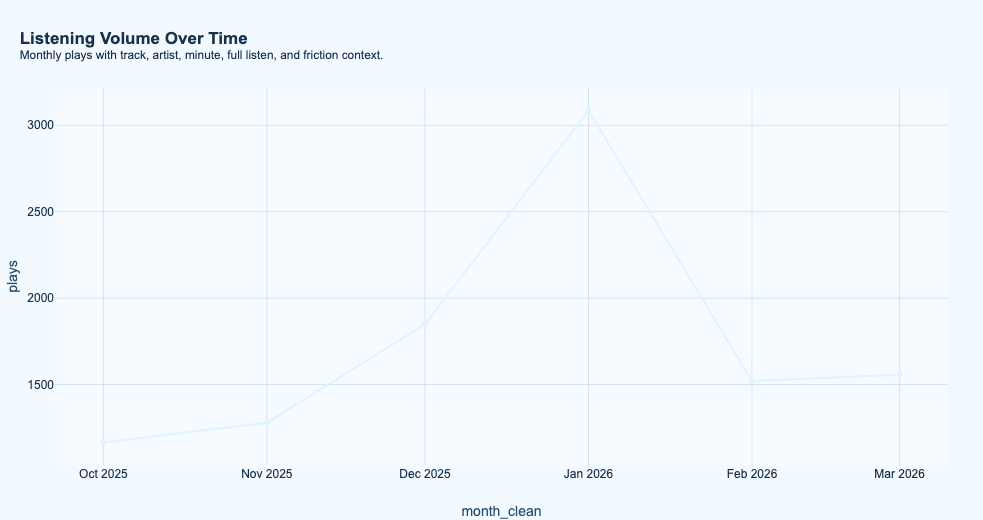

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/monthly_listening_volume.html.
Your busiest month was January 2026.


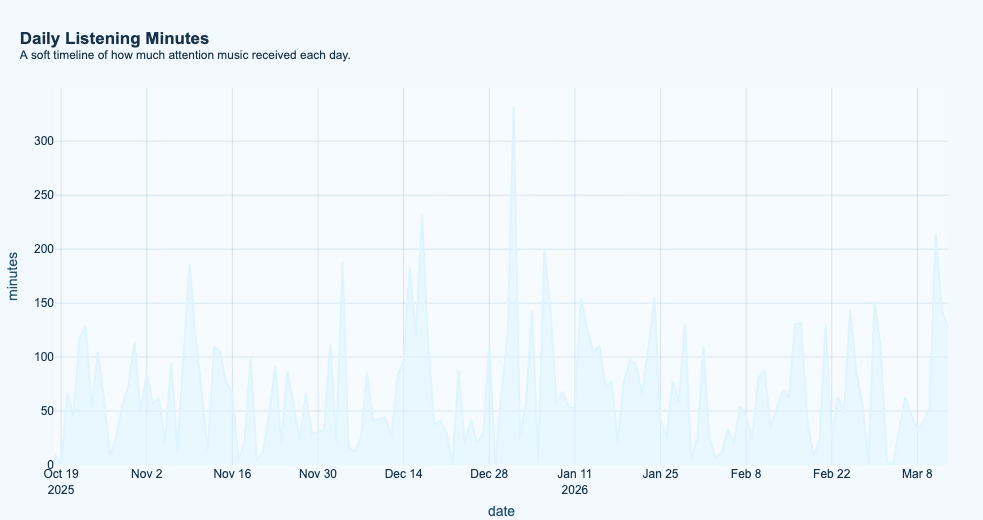

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/daily_minutes.html.
Your strongest listening day was 2026-01-01.


In [144]:
if "played_at" in plays.columns and plays["played_at"].notna().any():
    plays["month_clean"] = plays["played_at"].dt.to_period("M").dt.to_timestamp()
elif "month" in plays.columns:
    plays["month_clean"] = pandas.to_datetime(plays["month"], errors="coerce")
else:
    plays["month_clean"] = pandas.NaT

if "month_clean" in plays.columns and plays["month_clean"].notna().any():
    month = (
        plays.groupby("month_clean")
        .agg(
            plays=("event_id", "count") if "event_id" in plays.columns else ("month_clean", "size"),
            tracks=("track_key", "nunique") if "track_key" in plays.columns else ("month_clean", "size"),
            artists=("artist", "nunique") if "artist" in plays.columns else ("month_clean", "size"),
            minutes=("minutes", "sum") if "minutes" in plays.columns else ("month_clean", "size"),
            full_rate=("full_play", "mean") if "full_play" in plays.columns else ("month_clean", "size"),
            friction_rate=("friction", "mean") if "friction" in plays.columns else ("month_clean", "size"),
        )
        .reset_index()
    )

    month.to_csv(tab_root / "exploratory_monthly_listening.csv", index=False)

    chart = plot.line(
        month,
        x="month_clean",
        y="plays",
        markers=True,
        hover_data=["tracks", "artists", "minutes", "full_rate", "friction_rate"],
    )

    show_chart(
        chart,
        "monthly_listening_volume",
        "Listening Volume Over Time",
        "Monthly plays with track, artist, minute, full listen, and friction context.",
    )

    busiest = month.sort_values("plays", ascending=False).head(1)

    if not busiest.empty:
        print(f"Your busiest month was {busiest['month_clean'].iloc[0]:%B %Y}.")

if not days.empty and has_cols(days, ["date", "plays", "minutes"]):
    day_view = days.sort_values("date").copy()

    chart = plot.area(
        day_view,
        x="date",
        y="minutes",
        hover_data=["plays", "tracks", "artists", "top_artist", "top_genre", "full_rate", "friction_rate"],
    )

    show_chart(
        chart,
        "daily_minutes",
        "Daily Listening Minutes",
        "A soft timeline of how much attention music received each day.",
    )

    strongest = day_view.sort_values("minutes", ascending=False).head(1)

    if not strongest.empty:
        print(f"Your strongest listening day was {strongest['date'].iloc[0]:%Y-%m-%d}.")


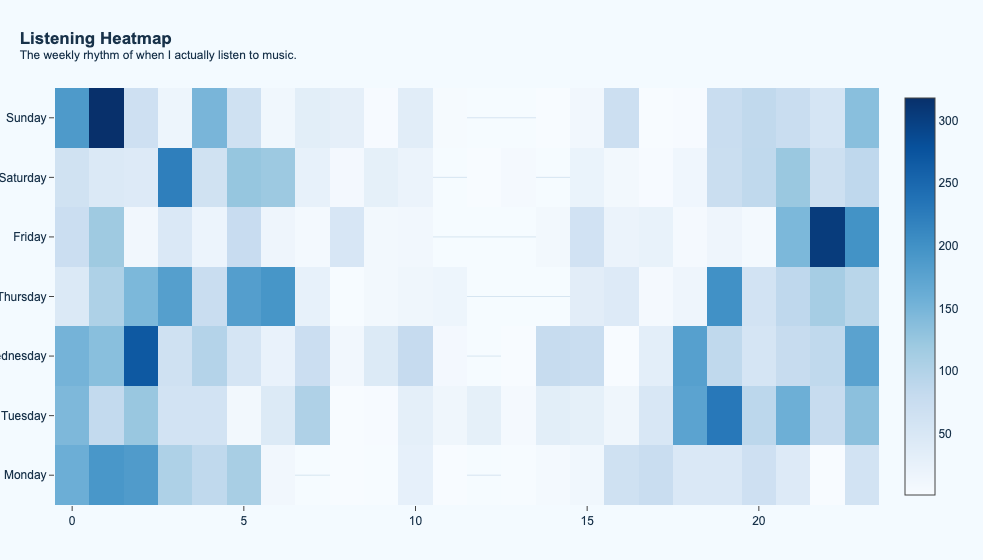

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/weekly_hour_heatmap.html.
My strongest listening pocket is Sunday at 1:00.


In [145]:
if has_cols(hours, ["weekday", "weekday_num", "hour", "plays"]):
    hour_view = hours.copy()
    order = hour_view.sort_values("weekday_num")[["weekday_num", "weekday"]].drop_duplicates()
    heat = hour_view.pivot_table(index="weekday", columns="hour", values="plays", aggfunc="sum").reindex(order["weekday"])

    chart = graph.Figure(
        data=graph.Heatmap(
            z=heat.values,
            x=heat.columns,
            y=heat.index,
            colorscale="Blues",
            hovertemplate="Day: %{y}<br>Hour: %{x}:00<br>Plays: %{z:,}<extra></extra>",
        )
    )

    show_chart(
        chart,
        "weekly_hour_heatmap",
        "Listening Heatmap",
        "The weekly rhythm of when I actually listen to music.",
        560,
    )

    strongest = hour_view.sort_values("plays", ascending=False).head(1)

    if not strongest.empty:
        print(f"My strongest listening pocket is {strongest['weekday'].iloc[0]} at {int(strongest['hour'].iloc[0])}:00.")

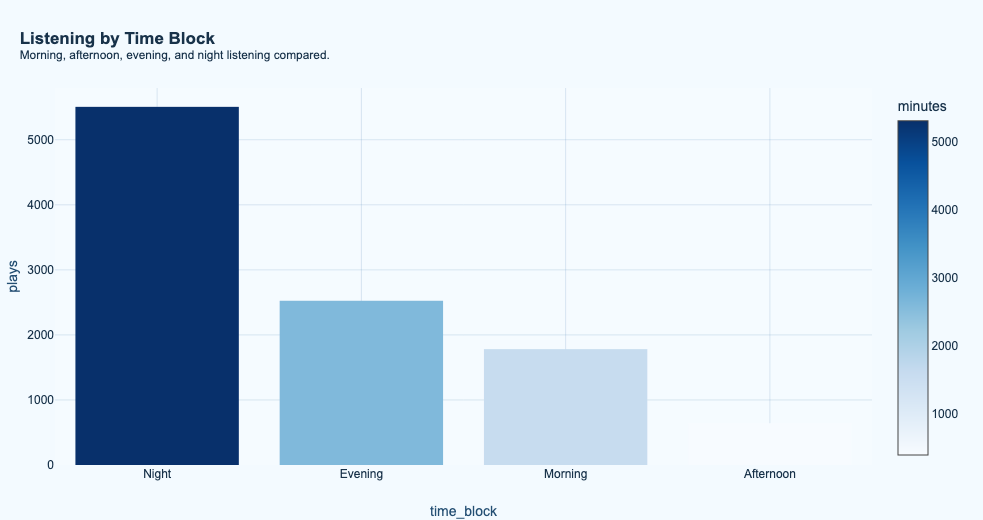

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/time_block_listening.html.


### Time Block Summary

,time_block,plays,minutes,full_rate,friction_rate
3,Night,5506,5303.472400,0.245187,0.769343
1,Evening,2525,2598.757450,0.255050,0.754455
2,Morning,1781,1601.919450,0.265020,0.741157
0,Afternoon,642,396.794133,0.121495,0.881620


In [146]:
if "time_block" in plays.columns:
    block = (
        plays.groupby("time_block")
        .agg(
            plays=("event_id", "count") if "event_id" in plays.columns else ("time_block", "size"),
            minutes=("minutes", "sum") if "minutes" in plays.columns else ("time_block", "size"),
            full_rate=("full_play", "mean") if "full_play" in plays.columns else ("time_block", "size"),
            friction_rate=("friction", "mean") if "friction" in plays.columns else ("time_block", "size"),
        )
        .reset_index()
        .sort_values("plays", ascending=False)
    )

    chart = plot.bar(
        block,
        x="time_block",
        y="plays",
        hover_data=["minutes", "full_rate", "friction_rate"],
        color="minutes",
        color_continuous_scale="Blues",
    )

    show_chart(
        chart,
        "time_block_listening",
        "Listening by Time Block",
        "Morning, afternoon, evening, and night listening compared.",
    )

    show_table(block, "Time Block Summary", 10)

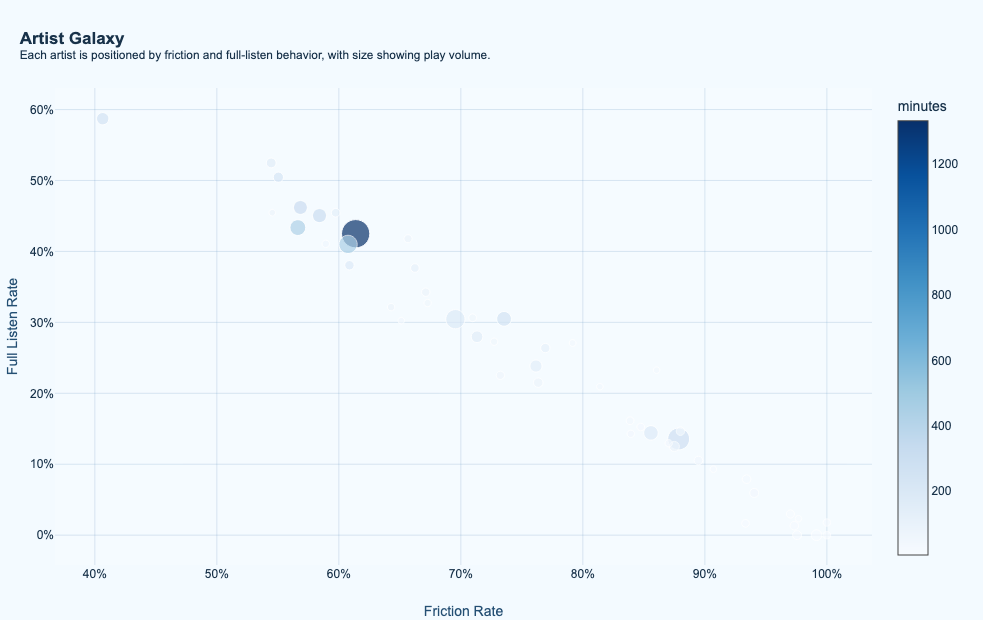

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/artist_galaxy.html.


### Core Artists

,artist,plays,tracks,albums,genres,minutes,good_plays,full_plays,friction_plays,first_play,last_play,active_days,source_top,good_rate,full_rate,friction_rate
0,ATEEZ,826,58,23,2,1332.040367,462,351,507,2025-10-20 01:00:49.113000,2026-03-13 22:00:55.416000,84,Library Playlist,0.559322,0.424939,0.613801
1,Unknown Artist,494,210,164,1,281.331567,105,67,434,2025-10-18 05:43:27.746000,2026-03-13 21:26:31.384000,64,Library Playlist,0.212551,0.135628,0.878543
2,Spiritual Concepts,381,6,2,2,187.772200,134,116,265,2025-10-31 08:17:14.289000,2026-03-10 23:35:18.023000,59,Other Source,0.351706,0.304462,0.695538
3,Yves,344,21,6,2,448.346917,169,141,209,2025-10-20 18:18:27.018000,2026-03-13 22:15:24.699000,42,Library Playlist,0.491279,0.409884,0.607558
4,XG,256,21,10,4,437.984517,156,111,145,2025-10-20 18:24:41.128000,2026-03-11 04:10:05.090000,67,Library Playlist,0.609375,0.433594,0.566406
5,IVE,223,23,13,2,243.680533,92,68,164,2025-11-02 20:40:41.156000,2026-03-13 17:53:31.600000,36,Library Playlist,0.412556,0.304933,0.735426
6,The Weeknd,215,30,4,2,176.999383,84,31,184,2025-10-18 06:07:18.993000,2026-03-11 02:39:47.259000,9,Library Playlist,0.390698,0.144186,0.855814
7,ITZY,202,15,10,5,306.668983,113,91,118,2025-11-02 20:37:44.716000,2026-03-13 22:04:38.329000,51,Library Playlist,0.559406,0.450495,0.584158
8,aespa,197,20,15,4,312.544417,114,91,112,2025-10-21 03:58:00.633000,2026-03-13 21:22:56.303000,51,Library Playlist,0.578680,0.461929,0.568528
9,ILLIT,155,15,8,2,248.223550,108,91,63,2025-11-22 23:06:33.441000,2026-03-13 22:12:45.377000,31,Library Playlist,0.696774,0.587097,0.406452


My most played artist, shockingly, is ATEEZ.


In [147]:
if has_cols(artists, ["artist", "plays", "full_rate", "friction_rate", "minutes"]):
    artist_view = artists.sort_values("plays", ascending=False).head(50).copy()

    chart = plot.scatter(
        artist_view,
        x="friction_rate",
        y="full_rate",
        size="plays",
        color="minutes",
        color_continuous_scale="Blues",
        hover_name="artist",
        hover_data=["tracks", "albums", "genres", "active_days", "source_top"],
    )

    chart.update_xaxes(tickformat=".0%", title="Friction Rate")
    chart.update_yaxes(tickformat=".0%", title="Full Listen Rate")

    show_chart(
        chart,
        "artist_galaxy",
        "Artist Galaxy",
        "Each artist is positioned by friction and full-listen behavior, with size showing play volume.",
        620,
    )

    show_table(artists.sort_values("plays", ascending=False), "Core Artists", 20)

    print(f"My most played artist, shockingly, is {top_artist}.")

## Genre Map
While genre labels are imperfect and pretty inconsistent but they are useful for understanding broad listening patterns. This section explores genre concentration, diversity, listening volume, and behavioral quality metrics across all genres.

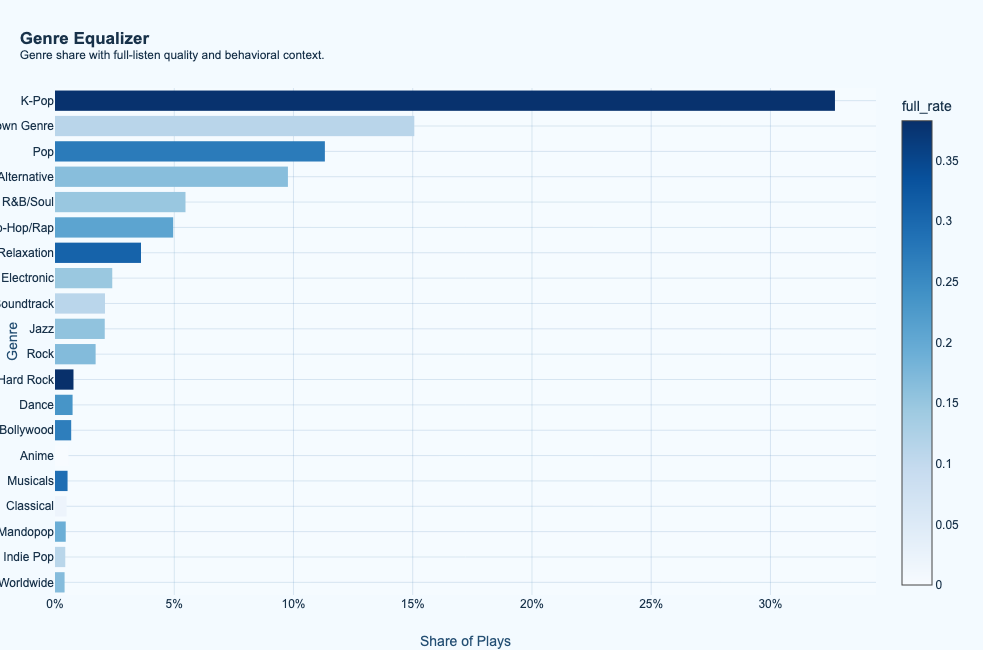

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/genre_equalizer.html.


### Genre Summary

,genre,plays,tracks,artists,minutes,full_plays,friction_plays,source_top,time_top,full_rate,friction_rate,share
0,K-Pop,3419,479,106,4650.558467,1299,2186,Library Playlist,Night,0.379936,0.639368,0.327052
1,Unknown Genre,1575,795,289,777.682483,176,1413,Search to Album,Night,0.111746,0.897143,0.150660
2,Pop,1183,336,111,1350.587200,323,869,Library Playlist,Night,0.273035,0.734573,0.113162
3,Alternative,1021,347,103,779.113500,168,859,Library Playlist,Night,0.164545,0.841332,0.097666
4,R&B/Soul,572,173,50,406.164000,85,493,Library Playlist,Night,0.148601,0.861888,0.054716
5,Hip-Hop/Rap,518,113,57,397.700733,108,415,Library Playlist,Night,0.208494,0.801158,0.049550
6,Relaxation,377,2,1,187.433600,116,261,Other Source,Morning,0.307692,0.692308,0.036063
7,Electronic,251,92,40,197.633067,37,217,Library Playlist,Night,0.147410,0.864542,0.024010
8,Soundtrack,219,86,53,104.701150,24,194,Library Playlist,Night,0.109589,0.885845,0.020949
9,Jazz,218,86,48,119.331433,34,186,Library Playlist,Night,0.155963,0.853211,0.020853


My leading genre is K-Pop.


In [148]:
if has_cols(genres, ["genre", "plays", "tracks", "artists", "minutes", "share"]):
    genre_view = genres.sort_values("plays", ascending=False).head(20).copy()

    chart = plot.bar(
        genre_view,
        x="share",
        y="genre",
        orientation="h",
        hover_data=["plays", "tracks", "artists", "minutes", "full_rate", "friction_rate", "source_top", "time_top"],
        color="full_rate",
        color_continuous_scale="Blues",
    )

    chart.update_xaxes(tickformat=".0%", title="Share of Plays")
    chart.update_yaxes(categoryorder="total ascending", title="Genre")

    show_chart(
        chart,
        "genre_equalizer",
        "Genre Equalizer",
        "Genre share with full-listen quality and behavioral context.",
        650,
    )

    show_table(genre_view, "Genre Summary", 20)

    print(f"My leading genre is {top_genre}.")

## Source Paths

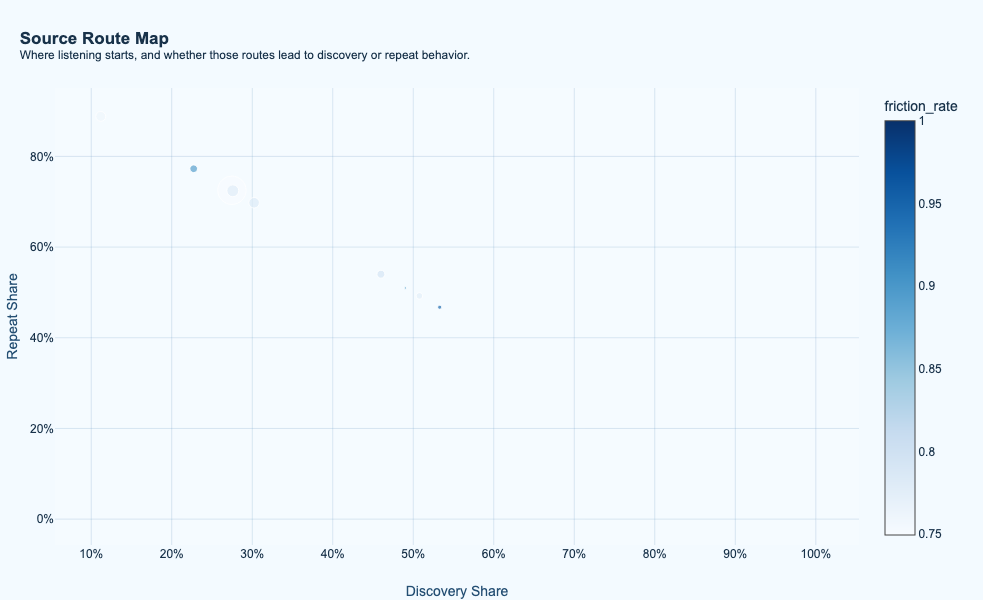

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/source_route_map.html.


### Source Route Summary

,source_label,source_role,plays,tracks,artists,genres,minutes,first_plays,repeat_plays,full_plays,friction_plays,play_share,discovery_share,repeat_share,full_rate,friction_rate
0,Library Playlist,Playlist,6252,1966,757,70,6506.477067,1718,4534,1632,4686,0.598049,0.274792,0.725208,0.261036,0.749520
1,Album Page,Browsing,1102,387,87,20,1052.245133,304,798,263,859,0.105414,0.275862,0.724138,0.238657,0.779492
2,Search to Album,Discovery,870,325,91,15,779.444283,263,607,191,679,0.083222,0.302299,0.697701,0.219540,0.780460
3,Other Source,Unknown,769,122,77,21,482.580733,86,683,195,584,0.073560,0.111834,0.888166,0.253576,0.759428
4,Search,Discovery,498,271,149,20,420.740783,229,269,112,394,0.047637,0.459839,0.540161,0.224900,0.791165
5,Playlist,Playlist,462,231,118,19,274.344867,105,357,61,411,0.044194,0.227273,0.772727,0.132035,0.889610
6,Now Playing,Playback,327,198,121,13,303.333067,166,161,74,253,0.031280,0.507645,0.492355,0.226300,0.773700
7,Radio or Station,Discovery,122,99,59,9,39.713933,65,57,8,115,0.011670,0.532787,0.467213,0.065574,0.942623
8,Artist Page,Browsing,51,36,20,10,41.068783,25,26,8,45,0.004879,0.490196,0.509804,0.156863,0.882353
9,Unknown Source,Unknown,1,1,1,1,0.994783,1,0,0,1,0.000096,1.000000,0.000000,0.000000,1.000000


The main source route for me is Library Playlist.


In [149]:
if has_cols(sources, ["source_label", "plays", "discovery_share", "repeat_share", "full_rate", "friction_rate"]):
    source_view = sources.sort_values("plays", ascending=False).copy()

    chart = plot.scatter(
        source_view,
        x="discovery_share",
        y="repeat_share",
        size="plays",
        color="friction_rate",
        color_continuous_scale="Blues",
        hover_name="source_label",
        hover_data=["source_role", "tracks", "artists", "genres", "minutes", "full_rate"],
    )

    chart.update_xaxes(tickformat=".0%", title="Discovery Share")
    chart.update_yaxes(tickformat=".0%", title="Repeat Share")

    show_chart(
        chart,
        "source_route_map",
        "Source Route Map",
        "Where listening starts, and whether those routes lead to discovery or repeat behavior.",
        600,
    )

    show_table(source_view, "Source Route Summary", 20)

    print(f"The main source route for me is {top_source}.")

## Sessions

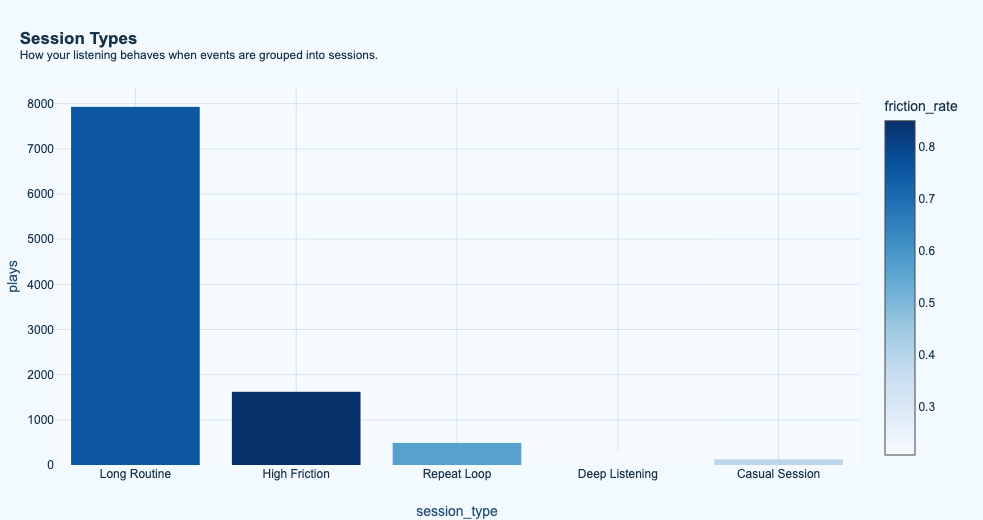

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/session_types.html.


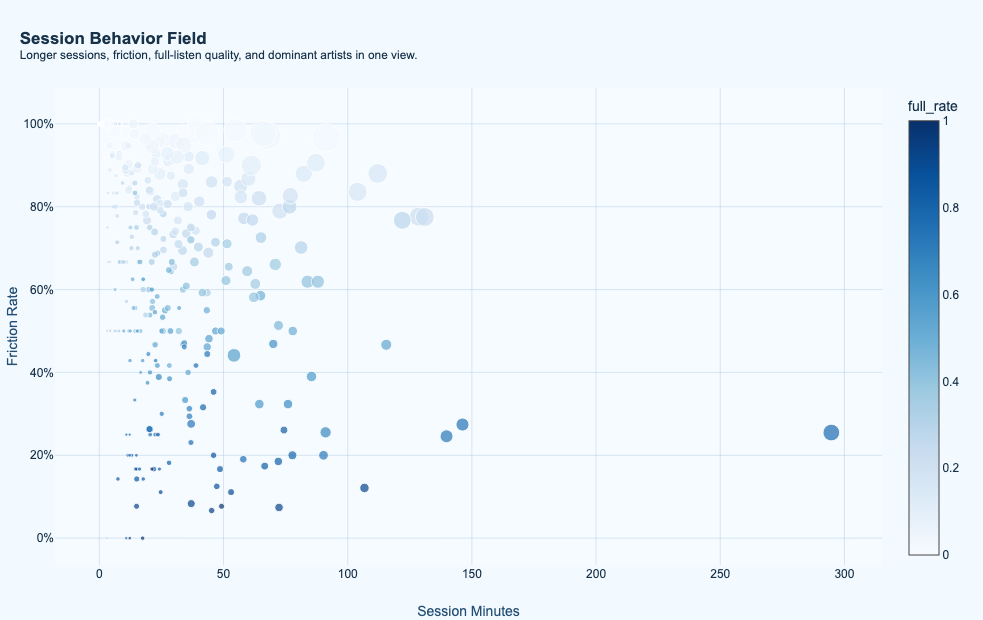

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/session_behavior_field.html.


### Session Type Summary

,session_type,sessions,plays,minutes,average_minutes,full_rate,friction_rate
3,Long Routine,126,7930,6307.857000,50.062357,0.250463,0.753360
2,High Friction,236,1621,1791.671600,7.591829,0.161582,0.849793
4,Repeat Loop,47,489,715.614217,15.225834,0.467653,0.564708
1,Deep Listening,28,288,821.373433,29.334765,0.823775,0.207064
0,Casual Session,11,126,264.427183,24.038835,0.606197,0.390268


My most common session pattern is Long Routine.


In [150]:
if has_cols(sessions, ["session_type", "plays", "minutes", "full_rate", "friction_rate", "start_hour"]):
    session_types = (
        sessions.groupby("session_type")
        .agg(
            sessions=("session", "count") if "session" in sessions.columns else ("session_type", "size"),
            plays=("plays", "sum"),
            minutes=("minutes", "sum"),
            average_minutes=("minutes", "mean"),
            full_rate=("full_rate", "mean"),
            friction_rate=("friction_rate", "mean"),
        )
        .reset_index()
        .sort_values("plays", ascending=False)
    )

    session_types.to_csv(tab_root / "exploratory_session_types.csv", index=False)

    chart = plot.bar(
        session_types,
        x="session_type",
        y="plays",
        color="friction_rate",
        color_continuous_scale="Blues",
        hover_data=["sessions", "minutes", "average_minutes", "full_rate"],
    )

    show_chart(
        chart,
        "session_types",
        "Session Types",
        "How your listening behaves when events are grouped into sessions.",
    )

    chart = plot.scatter(
        sessions,
        x="minutes",
        y="friction_rate",
        size="plays",
        color="full_rate",
        color_continuous_scale="Blues",
        hover_name="top_artist",
        hover_data=["session_type", "top_genre", "top_source", "start_hour", "tracks", "artists"],
    )

    chart.update_xaxes(title="Session Minutes")
    chart.update_yaxes(tickformat=".0%", title="Friction Rate")

    show_chart(
        chart,
        "session_behavior_field",
        "Session Behavior Field",
        "Longer sessions, friction, full-listen quality, and dominant artists in one view.",
        620,
    )

    show_table(session_types, "Session Type Summary", 20)

    print(f"My most common session pattern is {top_session}.")

## Lifecycle of Tracks

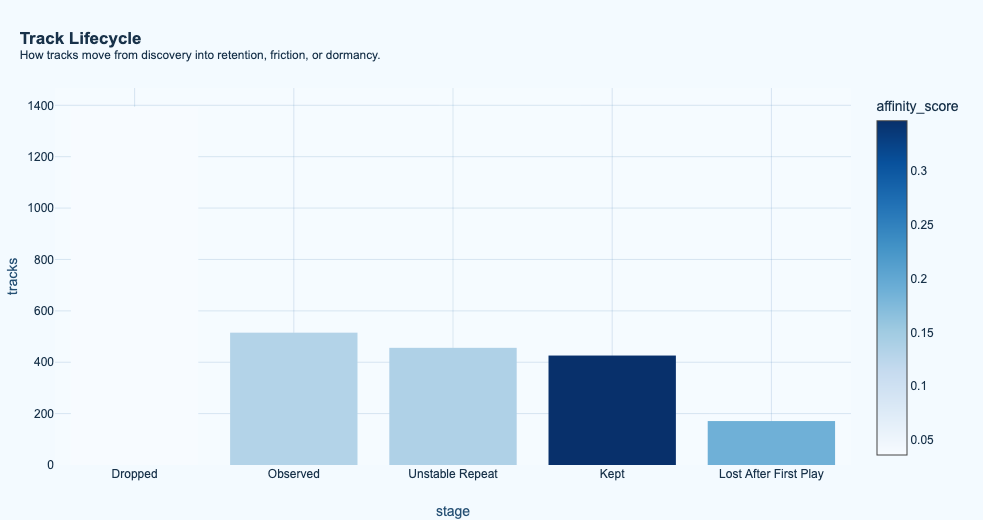

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/track_lifecycle.html.


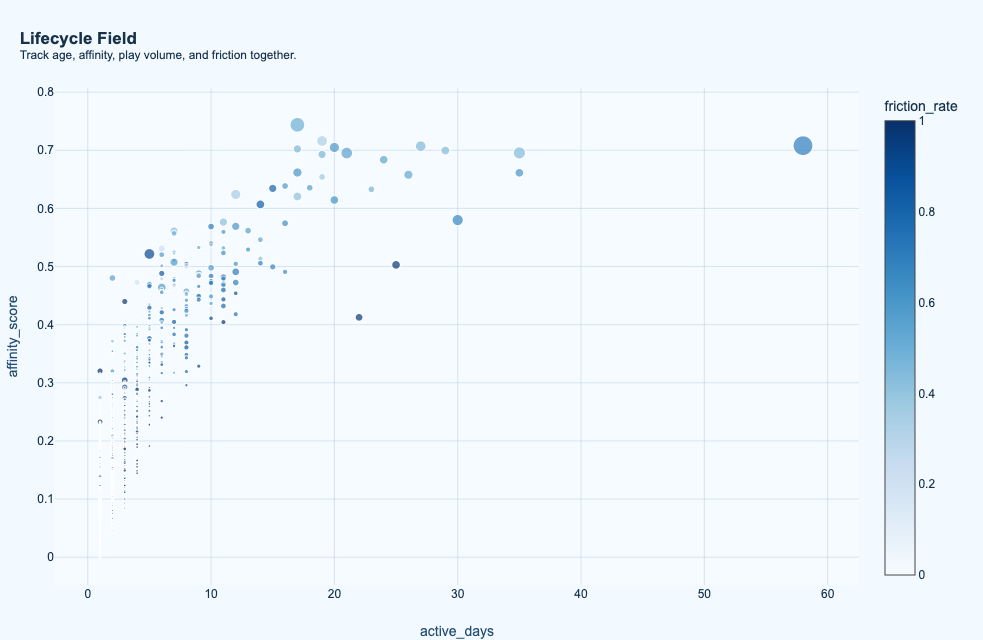

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/lifecycle_field.html.


### Lifecycle Summary

,stage,tracks,plays,minutes,active_days,full_rate,friction_rate,affinity_score
0,Dropped,1394,1606,222.932950,1.017934,0.000717,1.000000,0.036240
3,Observed,515,905,662.060367,1.438835,0.121974,0.874466,0.132274
4,Unstable Repeat,456,1994,397.160683,1.947368,0.012895,1.000000,0.136301
1,Kept,426,5778,8076.203600,5.676056,0.362163,0.644987,0.346299
2,Lost After First Play,171,171,542.585833,1.000000,1.000000,0.046784,0.187876


The largest lifecycle group is Dropped.


In [151]:
if has_cols(life, ["stage", "plays", "minutes", "active_days", "full_rate", "friction_rate", "affinity_score"]):
    stage = (
        life.groupby("stage")
        .agg(
            tracks=("track_key", "count") if "track_key" in life.columns else ("stage", "size"),
            plays=("plays", "sum"),
            minutes=("minutes", "sum"),
            active_days=("active_days", "mean"),
            full_rate=("full_rate", "mean"),
            friction_rate=("friction_rate", "mean"),
            affinity_score=("affinity_score", "mean"),
        )
        .reset_index()
        .sort_values("tracks", ascending=False)
    )

    stage.to_csv(tab_root / "exploratory_lifecycle_stage.csv", index=False)

    chart = plot.bar(
        stage,
        x="stage",
        y="tracks",
        color="affinity_score",
        color_continuous_scale="Blues",
        hover_data=["plays", "minutes", "active_days", "full_rate", "friction_rate"],
    )

    show_chart(
        chart,
        "track_lifecycle",
        "Track Lifecycle",
        "How tracks move from discovery into retention, friction, or dormancy.",
    )

    chart = plot.scatter(
        life,
        x="active_days",
        y="affinity_score",
        size="plays",
        color="friction_rate",
        color_continuous_scale="Blues",
        hover_name="display",
        hover_data=["stage", "artist", "genre", "full_rate", "candidate_class"],
    )

    show_chart(
        chart,
        "lifecycle_field",
        "Lifecycle Field",
        "Track age, affinity, play volume, and friction together.",
        640,
    )

    show_table(stage, "Lifecycle Summary", 20)

    largest_stage = stage.sort_values("tracks", ascending=False).head(1)

    if not largest_stage.empty:
        print(f"The largest lifecycle group is {largest_stage['stage'].iloc[0]}.")

### Behavior of Tracks

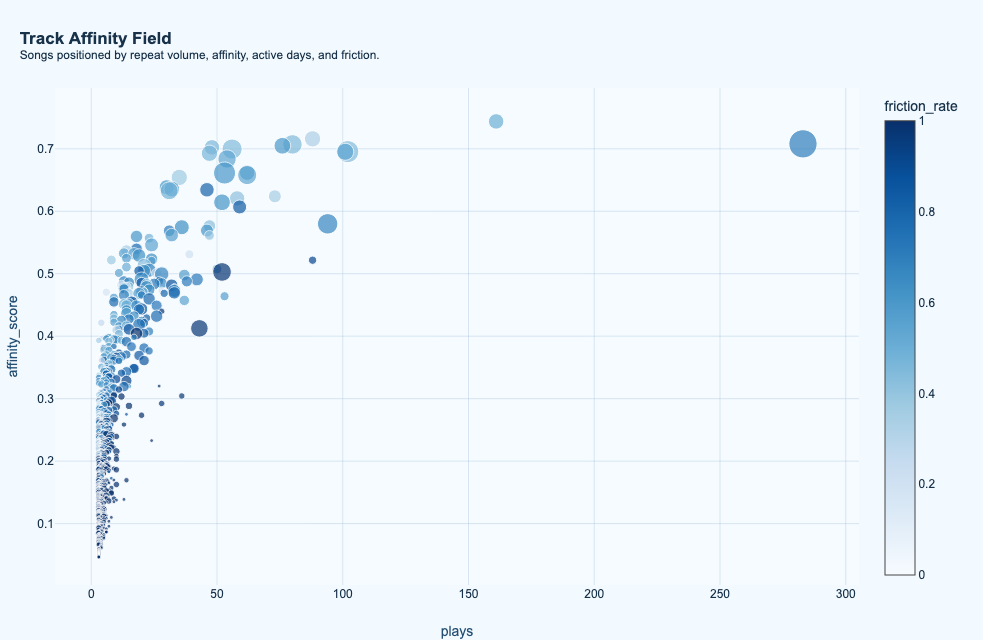

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/track_affinity_field.html.


### Highest Affinity Tracks

,display,artist,genre,plays,minutes,active_days,full_rate,friction_rate,affinity_score,candidate_class,source_top
0,NASA — ATEEZ,ATEEZ,K-Pop,161,333.828150,17,0.583851,0.496894,0.743849,Core Favorite,Album Page
1,little monster — ILLIT,ILLIT,K-Pop,88,151.348050,19,0.625000,0.329545,0.715960,Core Favorite,Library Playlist
2,Harp of Dreams — Spiritual Concepts,Spiritual Concepts,Relaxation,283,135.375983,58,0.300353,0.699647,0.707911,Core Favorite,Other Source
3,8-BIT HEART — ITZY,ITZY,K-Pop,80,158.564100,27,0.562500,0.450000,0.707085,Core Favorite,Library Playlist
4,Ex Machina — Yves,Yves,K-Pop,76,120.968033,20,0.486842,0.592105,0.704884,Core Favorite,Library Playlist
5,HALAZIA — ATEEZ,ATEEZ,K-Pop,48,99.041850,17,0.562500,0.458333,0.702372,Core Favorite,Library Playlist
6,Take Me Home — ATEEZ,ATEEZ,K-Pop,56,128.350583,29,0.589286,0.446429,0.699561,Core Favorite,Library Playlist
7,GALA — XG,XG,Pop,102,228.019550,35,0.509804,0.441176,0.695484,Core Favorite,Library Playlist
8,PS118 — JURIN ASAYA & Rapsody,JURIN ASAYA & Rapsody,Hip-Hop/Rap,101,149.937483,21,0.524752,0.544554,0.695230,Core Favorite,Library Playlist
9,Skin (SEONGHWA) — ATEEZ,ATEEZ,K-Pop,47,94.386750,19,0.531915,0.468085,0.692909,Core Favorite,Library Playlist


My highest affinity track is NASA — ATEEZ.


In [152]:
if has_cols(features, ["display", "plays", "full_rate", "friction_rate", "affinity_score", "active_days"]):
    track_view = features[features["plays"] >= 3].copy()

    chart = plot.scatter(
        track_view,
        x="plays",
        y="affinity_score",
        size="active_days",
        color="friction_rate",
        color_continuous_scale="Blues",
        hover_name="display",
        hover_data=["artist", "album", "genre", "minutes", "full_rate", "candidate_class", "source_top"],
    )

    show_chart(
        chart,
        "track_affinity_field",
        "Track Affinity Field",
        "Songs positioned by repeat volume, affinity, active days, and friction.",
        640,
    )

    favorites = features.sort_values(["affinity_score", "plays"], ascending=False).head(25)

    favorite_cols = [
        "display",
        "artist",
        "genre",
        "plays",
        "minutes",
        "active_days",
        "full_rate",
        "friction_rate",
        "affinity_score",
        "candidate_class",
        "source_top",
    ]

    favorite_cols = [col for col in favorite_cols if col in favorites.columns]

    show_table(favorites[favorite_cols], "Highest Affinity Tracks", 25)

    if not favorites.empty:
        print(f"My highest affinity track is {favorites['display'].iloc[0]}.")

## Friction Zone

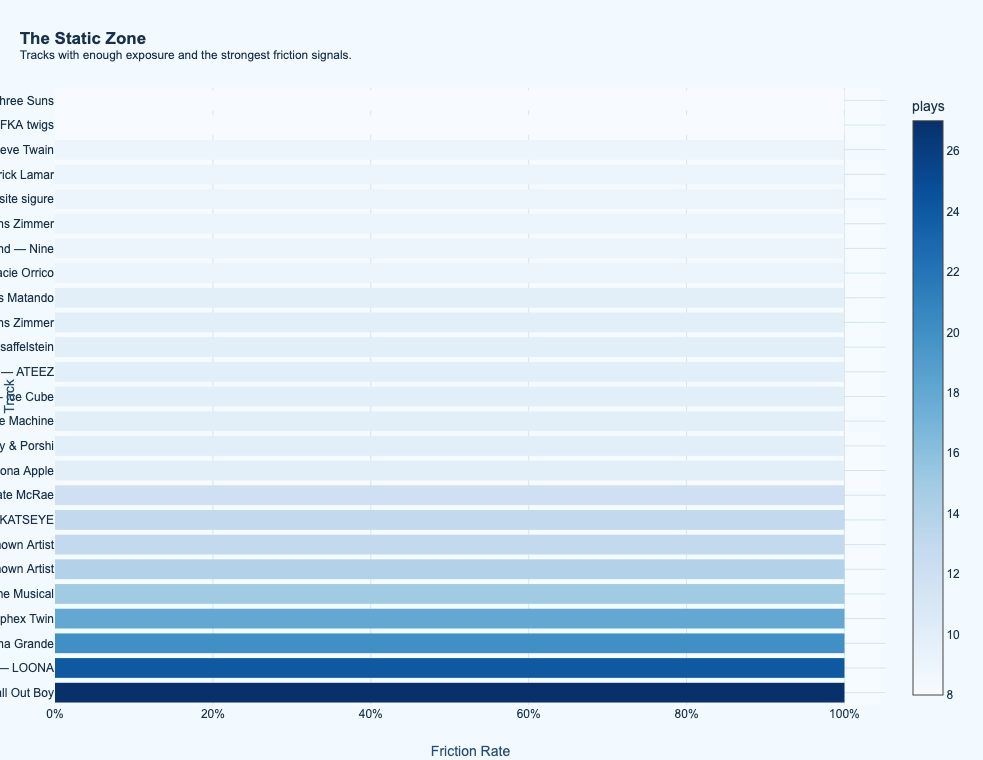

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/static_zone.html.


### High Friction Tracks

,display,artist,genre,plays,minutes,full_rate,friction_rate,candidate_class,ready_reason
207,Thnks fr th Mmrs — Fall Out Boy,Fall Out Boy,Alternative,27,6.268517,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
422,Stylish — LOONA,LOONA,Unknown Genre,24,6.426417,0.041667,1.000000,Overexposed or Unstable,High play count but elevated friction.
294,"No One Mourns the Wicked (feat. Andy Nyman, Courtney-Mae Briggs, Jeff Goldblum, Sharon D. Clarke & Jenna Boyd) — Wicked Movie Cast & Ariana Grande",Wicked Movie Cast & Ariana Grande,Unknown Genre,20,11.318700,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
123,#3 — Aphex Twin,Aphex Twin,Electronic,18,10.201117,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
271,El Tango De Roxanne — Aaron Tveit & Original Broadway Cast of Moulin Rouge! The Musical,Aaron Tveit & Original Broadway Cast of Moulin Rouge! The Musical,Soundtrack,15,1.557350,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
756,Tornado — Unknown Artist,Unknown Artist,Unknown Genre,14,0.757850,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
341,GOOD STUFF — Unknown Artist,Unknown Artist,Unknown Genre,13,0.671617,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
960,Internet Girl — KATSEYE,KATSEYE,Unknown Genre,13,0.429517,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
237,TIT FOR TAT — Tate McRae,Tate McRae,Pop,12,3.071567,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.
274,Love Ridden — Fiona Apple,Fiona Apple,Alternative,10,0.585217,0.000000,1.000000,Overexposed or Unstable,High play count but elevated friction.


The strongest repeated friction signal is Thnks fr th Mmrs — Fall Out Boy.


In [153]:
if has_cols(features, ["display", "plays", "friction_rate", "full_rate", "artist", "genre"]):
    friction = (
        features[features["plays"] >= 5]
        .sort_values(["friction_rate", "plays"], ascending=False)
        .head(25)
        .copy()
    )

    chart = plot.bar(
        friction,
        x="friction_rate",
        y="display",
        orientation="h",
        color="plays",
        color_continuous_scale="Blues",
        hover_data=["artist", "genre", "full_rate", "minutes", "candidate_class"],
    )

    chart.update_xaxes(tickformat=".0%", title="Friction Rate")
    chart.update_yaxes(categoryorder="total ascending", title="Track")

    show_chart(
        chart,
        "static_zone",
        "The Static Zone",
        "Tracks with enough exposure and the strongest friction signals.",
        760,
    )

    friction_cols = [
        "display",
        "artist",
        "genre",
        "plays",
        "minutes",
        "full_rate",
        "friction_rate",
        "candidate_class",
        "ready_reason",
    ]

    friction_cols = [col for col in friction_cols if col in friction.columns]

    show_table(friction[friction_cols], "High Friction Tracks", 25)

    if not friction.empty:
        print(f"The strongest repeated friction signal is {friction['display'].iloc[0]}.")

## Discovery

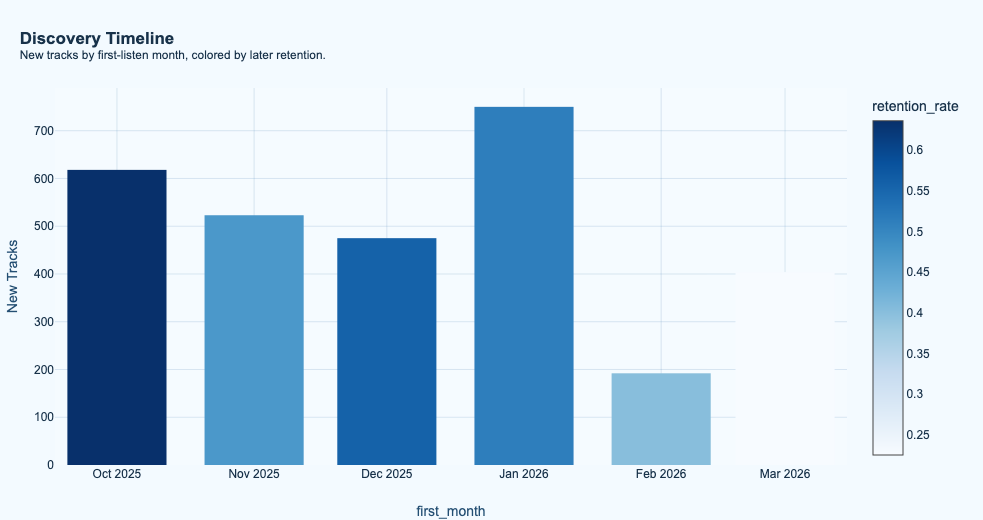

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/discovery_timeline.html.
My strongest discovery retention month was October 2025.


In [154]:
if has_cols(features, ["first_play", "retained", "plays", "display"]):
    discovery = features[features["first_play"].notna()].copy()
    discovery["first_month"] = discovery["first_play"].dt.to_period("M").dt.to_timestamp()

    discovery_month = (
        discovery.groupby("first_month")
        .agg(
            new_tracks=("track_key", "count") if "track_key" in discovery.columns else ("display", "count"),
            retained_tracks=("retained", "sum"),
            average_plays=("plays", "mean"),
            average_affinity=("affinity_score", "mean") if "affinity_score" in discovery.columns else ("plays", "mean"),
        )
        .reset_index()
    )

    discovery_month["retention_rate"] = discovery_month["retained_tracks"] / discovery_month["new_tracks"].replace(0, numpy.nan)

    discovery_month.to_csv(tab_root / "exploratory_discovery_month.csv", index=False)

    chart = plot.bar(
        discovery_month,
        x="first_month",
        y="new_tracks",
        color="retention_rate",
        color_continuous_scale="Blues",
        hover_data=["retained_tracks", "average_plays", "average_affinity"],
    )

    chart.update_yaxes(title="New Tracks")

    show_chart(
        chart,
        "discovery_timeline",
        "Discovery Timeline",
        "New tracks by first-listen month, colored by later retention.",
    )

    best_month = discovery_month.sort_values("retention_rate", ascending=False).head(1)

    if not best_month.empty:
        print(f"My strongest discovery retention month was {best_month['first_month'].iloc[0]:%B %Y}.")

In [155]:
## Recommendations

In [156]:
if not recommend_profile.empty:
    show_table(recommend_profile, "Recommendation System Profile", 20)

    if has_cols(recommend_profile, ["metric", "value"]) and recommend_profile["metric"].eq("ready_tracks").any():
        ready_tracks = recommend_profile.loc[recommend_profile["metric"].eq("ready_tracks"), "value"].iloc[0]
    else:
        ready_tracks = numpy.nan

    print(f"The recommendation layer has {number_text(ready_tracks)} ready tracks.")

### Recommendation System Profile

,metric,value,description
0,tracks,2962,Tracks available to the recommendation layer.
1,ready_tracks,1393,Tracks with enough signal to recommend again.
2,keep_close,426,High-confidence favorites or anchor tracks.
3,rediscover,171,Tracks worth resurfacing because they have useful signal but are not dominant.
4,bring_back,515,General recommendation candidates.
5,risky,456,Tracks with meaningful exposure but high skip behavior.
6,leave_alone,1394,Tracks that should not be prioritized right now.
7,recommendation_pairs,17980,Saved similar-track recommendation pairs.


The recommendation layer has 1,393 ready tracks.


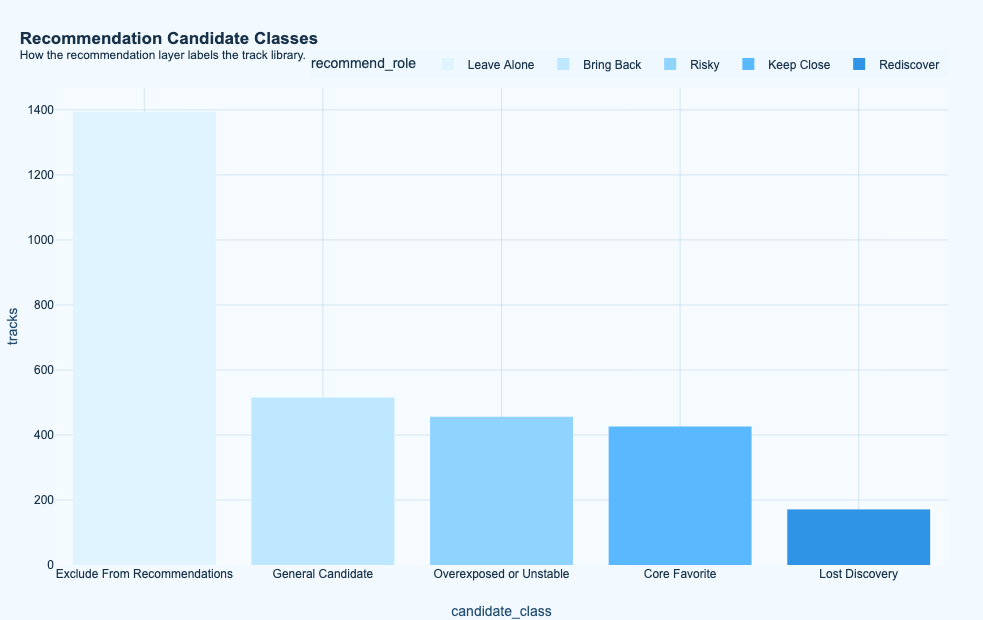

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/recommendation_candidate_classes.html.


### Recommendation Candidate Summary

,candidate_class,recommend_role,tracks,plays,recommend_score,quality_score,risk_score
1,Exclude From Recommendations,Leave Alone,1394,1606,0.001644,0.089290,1.000000
2,General Candidate,Bring Back,515,905,0.101150,0.202030,0.874466
4,Overexposed or Unstable,Risky,456,1994,0.070581,0.173908,1.000000
0,Core Favorite,Keep Close,426,5778,0.309975,0.390643,0.644987
3,Lost Discovery,Rediscover,171,171,0.232638,0.347585,0.046784


In [157]:
if has_cols(candidates, ["candidate_class", "recommend_role", "recommend_score", "quality_score", "risk_score"]):
    candidate_class = (
        candidates.groupby(["candidate_class", "recommend_role"])
        .agg(
            tracks=("track_key", "count") if "track_key" in candidates.columns else ("candidate_class", "size"),
            plays=("plays", "sum"),
            recommend_score=("recommend_score", "mean"),
            quality_score=("quality_score", "mean"),
            risk_score=("risk_score", "mean"),
        )
        .reset_index()
        .sort_values("tracks", ascending=False)
    )

    chart = plot.bar(
        candidate_class,
        x="candidate_class",
        y="tracks",
        color="recommend_role",
        hover_data=["plays", "recommend_score", "quality_score", "risk_score"],
    )

    show_chart(
        chart,
        "recommendation_candidate_classes",
        "Recommendation Candidate Classes",
        "How the recommendation layer labels the track library.",
        620,
    )

    show_table(candidate_class, "Recommendation Candidate Summary", 20)

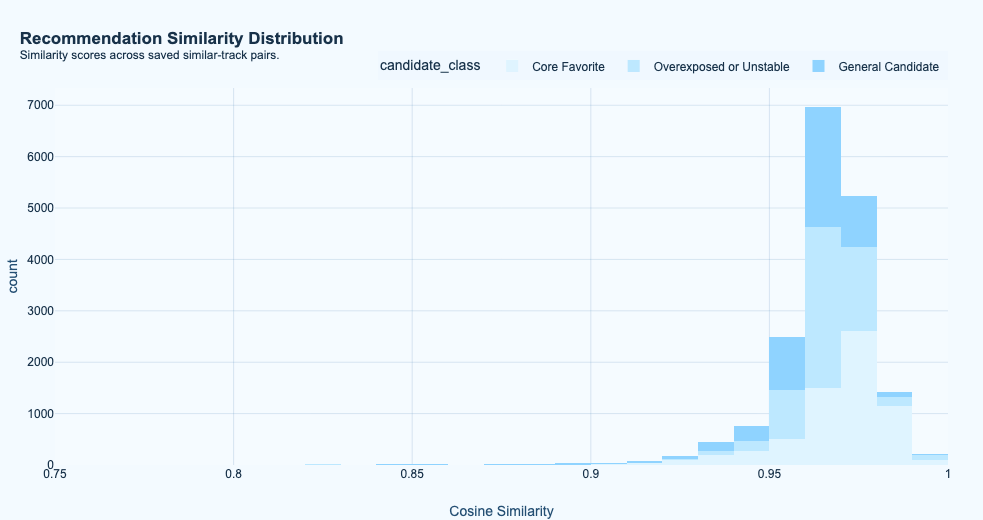

Saved chart to /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/exploratory_data_analysis/recommendation_similarity_distribution.html.


### Strongest Recommendation Pairs

,seed_display,candidate_display,similarity,recommend_role,recommend_score,affinity_score,plays,full_rate,friction_rate,candidate_class,recommend_reason
14927,higher — Jhené Aiko,my mine — Jhené Aiko,0.999888,Risky,0.062464,0.097637,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
14853,my mine — Jhené Aiko,higher — Jhené Aiko,0.999888,Risky,0.062318,0.097117,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
16192,#6 — Aphex Twin,#5 — Aphex Twin,0.999859,Risky,0.022378,0.086228,4,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 4 plays but a high skip rate of 100.0%.
15914,#5 — Aphex Twin,#6 — Aphex Twin,0.999859,Risky,0.021592,0.083421,4,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 4 plays but a high skip rate of 100.0%.
17043,#8 — Aphex Twin,#10 — Aphex Twin,0.998987,Risky,0.015430,0.071290,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
17022,#10 — Aphex Twin,#8 — Aphex Twin,0.998987,Risky,0.015138,0.070249,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
14928,higher — Jhené Aiko,you vs them — Jhené Aiko,0.998348,Risky,0.062330,0.097158,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
14913,you vs them — Jhené Aiko,higher — Jhené Aiko,0.998348,Risky,0.062318,0.097117,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
14914,you vs them — Jhené Aiko,my mine — Jhené Aiko,0.998252,Risky,0.062464,0.097637,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.
14854,my mine — Jhené Aiko,you vs them — Jhené Aiko,0.998252,Risky,0.062330,0.097158,3,0.000000,1.000000,Overexposed or Unstable,This needs caution because it has 3 plays but a high skip rate of 100.0%.


The strongest saved recommendation pair is higher — Jhené Aiko into my mine — Jhené Aiko.


In [158]:
if has_cols(recommendations, ["seed_display", "candidate_display", "similarity", "recommend_score", "candidate_class"]):
    chart = plot.histogram(
        recommendations,
        x="similarity",
        nbins=40,
        color="candidate_class",
        hover_data=["recommend_role"],
    )

    chart.update_xaxes(title="Cosine Similarity")

    show_chart(
        chart,
        "recommendation_similarity_distribution",
        "Recommendation Similarity Distribution",
        "Similarity scores across saved similar-track pairs.",
    )

    strongest_pairs = recommendations.sort_values(["similarity", "recommend_score"], ascending=False).head(20)

    pair_cols = [
        "seed_display",
        "candidate_display",
        "similarity",
        "recommend_role",
        "recommend_score",
        "affinity_score",
        "plays",
        "full_rate",
        "friction_rate",
        "candidate_class",
        "recommend_reason",
    ]

    pair_cols = [col for col in pair_cols if col in strongest_pairs.columns]

    show_table(strongest_pairs[pair_cols], "Strongest Recommendation Pairs", 20)

    if not strongest_pairs.empty:
        print(f"The strongest saved recommendation pair is {strongest_pairs['seed_display'].iloc[0]} into {strongest_pairs['candidate_display'].iloc[0]}.")

## **Conclusion**
Even though there are thousands of tracks in the dataset, only a small subset become lasting favorites. Most tracks fall into dropped, observed, or unstable lifecycle stages, suggesting that discovery activity is high but retention is selective. The recommendation layer is supported by a large behavioral feature space and identifies over one thousand tracks with enough signal to make meaningful recommendations. Overall, the data suggests a listener who explores broadly, filters aggressively, and returns repeatedly to a relatively stable co

In [159]:
summary = pandas.DataFrame(
    [
        {
            "question": "Who am I as a listener?",
            "answer": f"I am a {listener}, and my listening behavior is {selectivity}.",
        },
        {
            "question": "What anchors my taste?",
            "answer": f"My center of gravity is {top_artist}, {top_genre}, and {top_source}.",
        },
        {
            "question": "When do I listen most?",
            "answer": f"My most common listening time block is {top_block}.",
        },
        {
            "question": "How do my sessions behave?",
            "answer": f"My most common session type is {top_session}.",
        },
        {
            "question": "How much data supports this?",
            "answer": f"The analysis uses {total:,} listening events, {track_count:,} tracks, {artist_count:,} artists, {genre_count:,} genres, and {active_days:,} active days.",
        },
        {
            "question": "How real is the recommender?",
            "answer": f"The recommendation tables contain {len(candidates):,} candidates and {len(recommendations):,} saved similar-track pairs.",
        },
    ]
)

summary.to_csv(tab_root / "exploratory_personal_summary.csv", index=False)
show_table(summary, "Personal Summary", 20)

### Personal Summary

,question,answer
0,Who am I as a listener?,"I am a a return-driven listener, and my listening behavior is highly selective."
1,What anchors my taste?,"My center of gravity is ATEEZ, K-Pop, and Library Playlist."
2,When do I listen most?,My most common listening time block is Night.
3,How do my sessions behave?,My most common session type is Long Routine.
4,How much data supports this?,"The analysis uses 10,454 listening events, 2,962 tracks, 996 artists, 71 genres, and 143 active days."
5,How real is the recommender?,"The recommendation tables contain 2,962 candidates and 17,980 saved similar-track pairs."
